# 응용 모의 제6회 | 에너지 사용량과 요금 미납 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys

FOLDER = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(FOLDER.parent / "공통"))
from analysis import Context

ctx = Context(FOLDER)

## 1. 회귀 설계와 조건별 개선

**상황을 이해하기**

전력 사용량 점수는 학습용 소비 지표이며 미납은 요금을 기한 내 내지 않은 사건입니다.

**관측 단위와 판단 목적**

회귀 한 행은 하루로 날짜순입니다. 분류 관측은 별도 독립 계약이며 회귀 행과 연결하지 않습니다. 과거에서 미래로 예측하고 평균 예측 개선과 오차 공분산 보정을 구분합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 관측 식별자; 예측 입력에서 제외 |
| `target` | 전력 사용량 점수; 예측할 반응 |
| `outdoor_temp` | 외기 온도의 편차 지수; 원 측정값/표본 표준화 아님 |
| `occupancy` | 공간 이용 정도의 편차 지수; 원 측정값/표본 표준화 아님 |
| `insulation` | 단열 성능의 편차 지수; 원 측정값/표본 표준화 아님 |
| `equipment` | 사용 장비 규모의 편차 지수; 원 측정값/표본 표준화 아님 |

**고정 분석 조건**

회귀 행은 날짜순 등간격이며 가까운 날의 오차가 관련될 수 있다. 무작위 분할을 사용하지 않고 공분산 보정과 평균 예측 개선을 구분한다. regression.csv의240행은 시간순 일별 관측을 가정한 고정 합성 자료다. 목표 target의 단위는 전력 사용량 점수이며 id는 식별자다. 입력은 outdoor_temp, occupancy, insulation, equipment다. 입력은 고정 업무 기준 대비 편차 지수이므로 음수가 가능하며 표본 전체에서 미리 추정한 표준화 값이 아니다. 앞70%/뒤30%의 시간순 분할과 학습 TimeSeriesSplit3-fold를 사용한다. 후보 선택 기준은 동일 원반응 단위 CV R² 최대다. 기본 대치·표준화·선형 모형, VIF5, AIC/BIC 후진 선택과 학습 시계열 분할 및 HAC 공분산 후보를 사전 지정한다. 모든 학습 통계·변수선택·행 처리는 폴드 안에서 적합한다. 유의수준은5%이며 반복 진단은 탐색적 개별검정으로 보고한다. 최종평가로 후보나 가정을 골라서는 안 된다.

### 1-1

**문제 (6점)**

관측 단위·목표 척도·예측 시점과 입력의 역할을 정리하고 결측·분포·공선성 후보를 탐색하시오. 지정 분할의 원행 위치를 남기고 전체 자료 대치나 식별자 입력이 왜 부적절한지 설명하시오.

**핵심 산출물**

관측·열 역할표, 결측 요약, 학습/평가 원행 위치

**풀이 근거와 읽는 순서**

원행 위치를 먼저 봉인하고 결측 대치·스케일·선택은 Pipeline.fit 안에 둔다.

id는 의미 없는 식별자이며 test는 최종 보고만 한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [2]:
ctx.run("1-1", "reg_design")

회귀 자료와 평가 설계
입력은 실제 면적·거리 등의 원 측정값이 아니라 고정 기준 대비 편차 지수입니다. id는 관측 식별자이고 target만 예측할 반응입니다.

자료·분할


,항목,값
0,전체 행,240
1,학습 행,168
2,최종 평가 행,72
3,분리 방식,chronological



열별 결측 수


,항목,값
0,outdoor_temp,0
1,occupancy,8
2,insulation,0
3,equipment,0



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 1-2

**문제 (6점)**

기본 전처리와 선형 기준 모형을 학습에 적합하고 학습/CV R², 계수 t 검정·전체 F 검정·AIC·BIC를 제시하시오. 계수·설명력·일반화 성능의 의미와 기본 추론 가정을 구분하시오. 최종평가는 아직 사용하지 마시오.

**핵심 산출물**

학습·CV R², 계수 t·전체 F, AIC·BIC와 추론 조건

**풀이 근거와 읽는 순서**

R²와 수정 R²는 적합 설명력, CV R²는 학습 밖 예측 평가다.

t는 개별 계수, F는 지정 전체 기울기 가설이다.

고전적 추론은 올바른 사양·독립·등분산·정규 오차에 조건부이며 y 자체 정규성을 요구하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [3]:
ctx.run("1-2", "reg_baseline")

기준 회귀모형의 적합 결과
계수 검정은 학습 적합의 조건부 추론입니다. 학습 R²와 CV R²를 구분하고 최종 평가 자료는 아직 사용하지 않습니다.

학습 성능


,항목,값
0,r2,0.642838
1,rmse,1.5919
2,mae,1.26319
3,cv_r2,0.366016



계수·검정·구간


,term,coefficient,standard_error,t_statistic,p_value,ci_lower,ci_upper,reject_h0
0,Intercept,4.70108,0.124687,37.7031,2.08937e-82,4.45487,4.94729,True
1,numeric__outdoor_temp,1.262,0.957927,1.31742,0.189546,-0.629551,3.15354,False
2,numeric__occupancy,-0.475683,0.124997,-3.80554,0.000199868,-0.722506,-0.22886,True
3,numeric__insulation,0.842578,0.957803,0.879699,0.380317,-1.04872,2.73388,False
4,numeric__equipment,0.0510809,0.125672,0.406462,0.684937,-0.197074,0.299236,False



학습 적합·정보량


,항목,값
0,r2,0.642838
1,adjusted_r2,0.634073
2,r2_kind,centered
3,f_statistic,73.3438
4,f_p_value,1.93208e-35
5,f_kind,classical overall F
6,df_model,4
7,df_resid,163
8,n_samples,168
9,aic,642.979



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 1-3

**문제 (6점)**

기준 모형의 선형 사양·잔차 정규성·등분산성과 관측 설계에 맞는 독립성/자기상관을 진단하시오. 가설·통계량·p값·가정·판정과 잔차/분위수/영향도 그림을 보고하시오. VIF와 Cook 영향도의 대상을 구분하고 이상 관측을 자동으로 오류라고 단정하지 마시오.

**핵심 산출물**

가정별 검정표·그림, VIF·Cook의 해석 대상

**풀이 근거와 읽는 순서**

정규성은 적합 잔차의 JB, 사양은 RESET, 등분산은 Koenker/BP를 사용한다.

IID의 DW는 기술값만, 명시 시간순은 BG를 사용한다.

가설을 각각 분리하고 탐색적 개별 p값을 해석한다.

VIF는 설계 열, Cook은 관측의 추정 영향이며 비기각은 가정 증명이 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

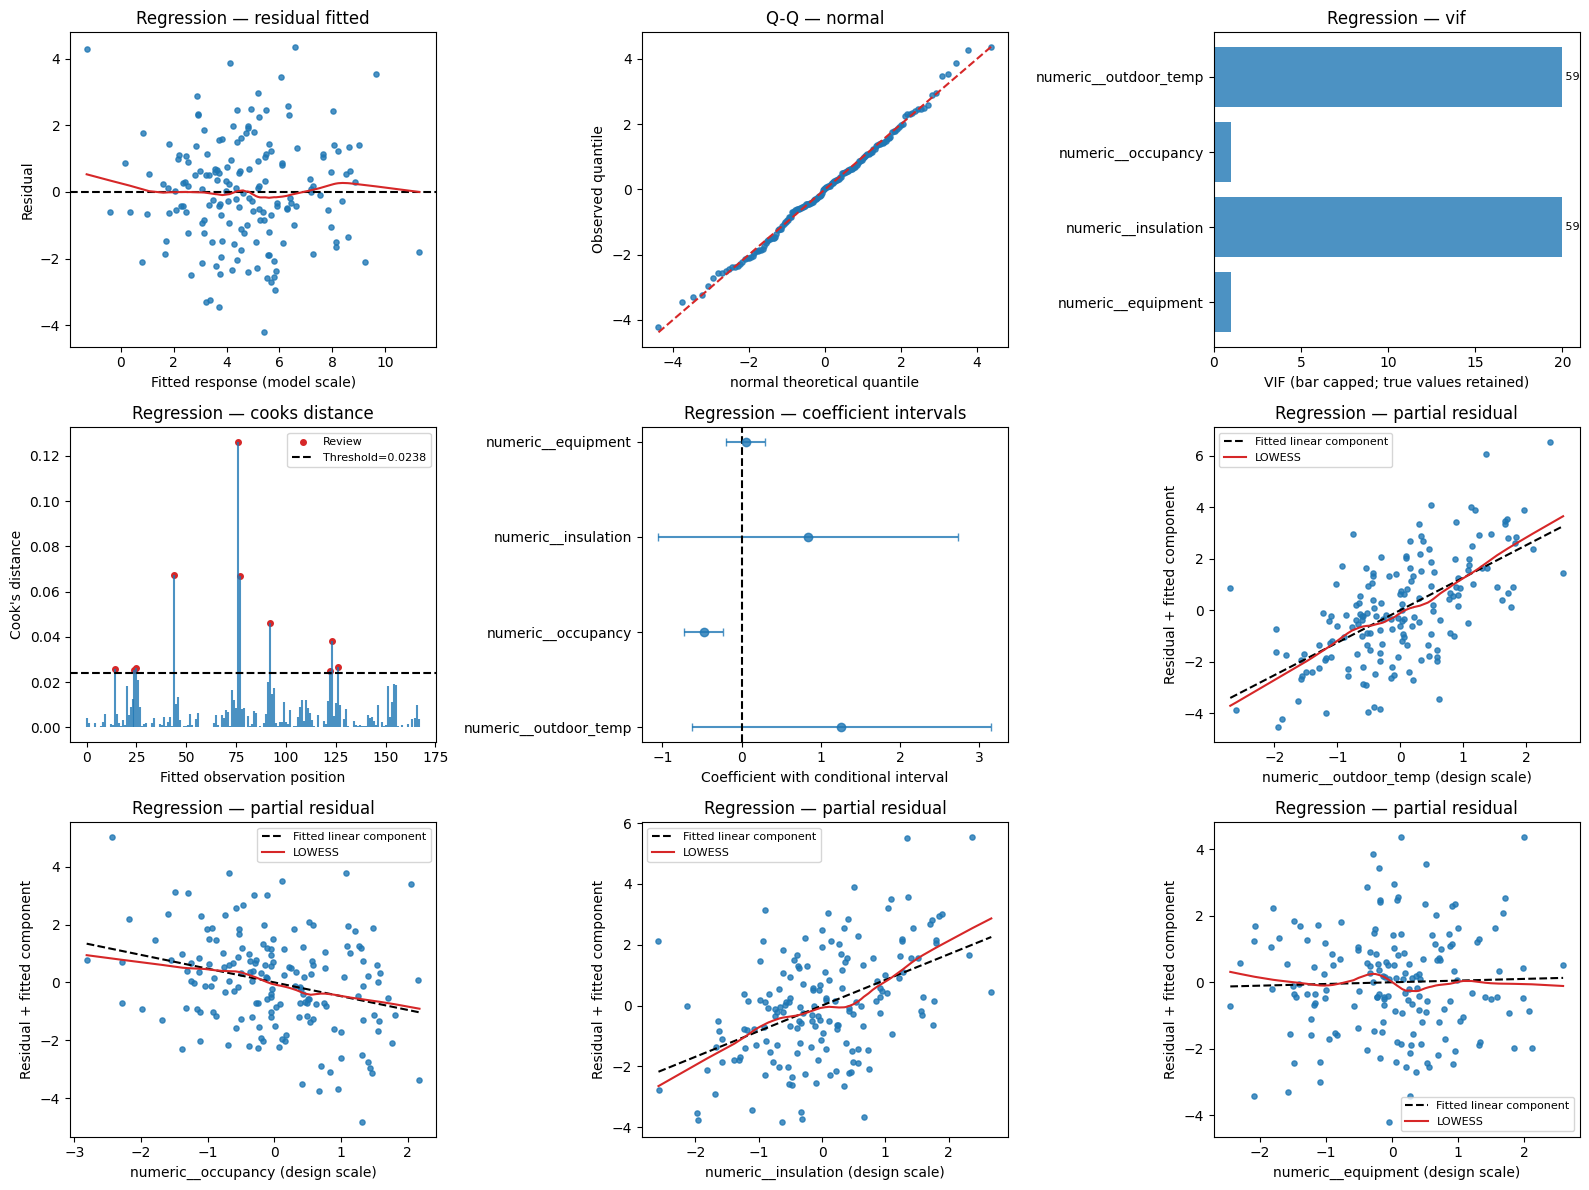

기준 모형의 가정과 영향도
가정별 귀무가설을 따로 읽습니다. 기각하지 못해도 가정이 참임을 증명하지 않습니다. VIF는 변수 중복, Cook은 관측 영향입니다.

normality


,test,statistic,p_value,reject_h0,df_num,df_den
0,jarque_bera,0.458934,0.794957,False,None,None



linearity


,test,statistic,p_value,reject_h0,df_num,df_den
0,RESET F,2.37961,0.0958357,False,2,161



heteroscedasticity


...


collinearity


,feature,vif,tolerance,flag
0,numeric__outdoor_temp,59.0232,0.0169425,True
1,numeric__occupancy,1.00499,0.995039,False
2,numeric__insulation,59.0078,0.0169469,True
3,numeric__equipment,1.01586,0.984386,False



영향 관측 검토: Cook 값 상위 8행(전체는 JSON)


,position,row_label,residual,studentized_internal,studentized_external,leverage,...,outlier_p,adjusted_outlier_p,cook_flag,leverage_flag,studentized_flag,outlier_reject
76,76,76,4.28597,2.75976,2.8179,0.0765695,...,0.00543621,0.913283,True,True,False,False
44,44,44,4.36502,2.75991,2.81806,0.0422962,...,0.0054336,0.912845,True,False,False,False
77,77,77,3.8868,2.46999,2.50982,0.051926,...,0.0130611,1,True,False,False,False
92,92,92,3.55175,2.24728,2.27592,0.0436482,...,0.024161,1,True,False,False,False
123,123,123,-3.30787,-2.09096,-2.11307,0.0418028,...,0.0361272,1,True,False,False,False
126,126,126,-4.21562,-2.63337,-2.68297,0.0188194,...,0.00805437,1,True,False,False,False
25,25,25,-3.23064,-2.03057,-2.05043,0.030849,...,0.0419342,1,True,False,False,False
14,14,14,-1.81667,-1.17515,-1.17654,0.0850122,...,0.241107,1,True,True,False,False



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


In [4]:
ctx.run("1-3", "reg_diagnostics")

### 1-4

**문제 (6점)**

동일 학습 행·동일 원반응에서 AIC와 BIC로 후진 변수선택을 수행하고 제거 경로·남은 특성을 비교하시오. VIF 제거와의 차이, 서로 다른 y변환·관측 행의 정보량을 직접 비교하는 오류, 변수선택 후 추론의 한계를 설명하시오.

**핵심 산출물**

AIC/BIC 선택 경로와 남은 열, 동일 행·반응 확인

**풀이 근거와 읽는 순서**

AIC=-2ll+2k, BIC=-2ll+log(n)k의 감소를 따라 탐욕적 후진 선택한다.

같은 행/반응의 비교다.

최적 부분집합 보장이나 선택 후 추론 보정은 없으며 CV 폴드에서 다시 선택해야 한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [5]:
ctx.run("1-4", "reg_selection")

AIC·BIC 변수 선택 비교
AIC/BIC는 같은 행·같은 반응 좌표계에서 비교합니다. 여기에 표시한 전체 학습 선택을 다음 CV의 각 학습 fold에서 다시 수행합니다.

AIC 선택 요약


""



AIC 선택 경로


,step,removed,aic,bic,accepted
0,0,None,642.979,658.598,True
1,1,numeric__outdoor_temp,642.758,655.254,False
2,1,numeric__occupancy,655.279,667.775,False
3,1,numeric__insulation,641.774,654.27,False
4,1,numeric__equipment,641.149,653.645,True
5,2,numeric__outdoor_temp,640.895,650.267,False
6,2,numeric__occupancy,653.481,662.853,False
7,2,numeric__insulation,639.954,649.326,True
8,3,numeric__outdoor_temp,805.708,811.956,False
9,3,numeric__occupancy,651.868,658.116,False



AIC 선택 변수


...


BIC 선택 경로


,step,removed,aic,bic,accepted
0,0,None,642.979,658.598,True
1,1,numeric__outdoor_temp,642.758,655.254,False
2,1,numeric__occupancy,655.279,667.775,False
3,1,numeric__insulation,641.774,654.27,False
4,1,numeric__equipment,641.149,653.645,True
5,2,numeric__outdoor_temp,640.895,650.267,False
6,2,numeric__occupancy,653.481,662.853,False
7,2,numeric__insulation,639.954,649.326,True
8,3,numeric__outdoor_temp,805.708,811.956,False
9,3,numeric__occupancy,651.868,658.116,False



BIC 선택 변수


,변수
0,numeric__outdoor_temp
1,numeric__occupancy



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 1-5

**문제 (6점)**

사전 지정 전처리·변수선택·대안 모형을 학습 CV 내부에서 튜닝하시오. 후보별 원단위 CV R²·선택 파라미터·실패 여부와 분할을 보고하고 하나를 선택하시오. 특히 학습 시계열 분할 및 HAC 공분산 후보의 적용 조건과 처리 단위를 설명하시오.

**핵심 산출물**

동일 CV 후보 비교표, 선택 설정, 적용 조건

**풀이 근거와 읽는 순서**

원단위 CV R² 최대를 선택하며 후보별 clone은 각 학습 폴드에서 모든 처리를 새로 적합한다.

기준 대비 진단과 점수를 함께 보고 test로 모델을 바꾸지 않는다.

HAC는 오차 자기상관에 대한 공분산 보정이며 평균 예측이나 R²를 바꾸는 전처리가 아니다.

자기상관이 남으면 후속 시계열/동적 평균 사양을 검토하고 모든 가정이 해결됐다고 주장하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

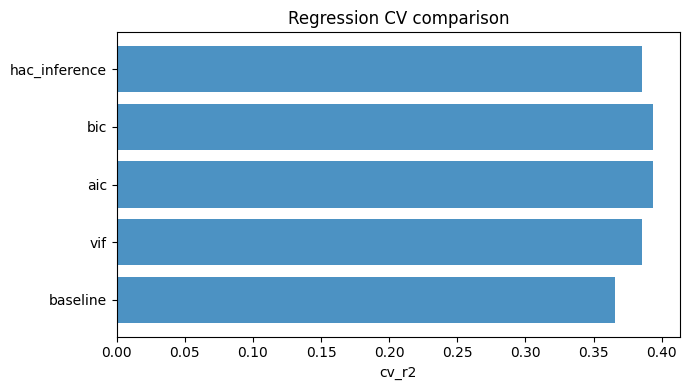

학습 CV에서 처리 후보 선택
CV R²가 가장 큰 후보를 선택했습니다. 선택에 최종 평가 점수를 사용하지 않습니다.

동일 fold의 CV 비교


,name,cv_r2,best_params
0,baseline,0.366016,{'degree': 1}
1,vif,0.385266,{'degree': 1}
2,aic,0.393782,{'degree': 1}
3,bic,0.393782,{'degree': 1}
4,hac_inference,0.385266,{'degree': 1}



선택 후보


,항목,값
0,선택,aic
1,평가 자료 사용,없음



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


In [6]:
ctx.run("1-5", "reg_tuning")

### 1-6

**문제 (6점)**

선택 이후에만 기준/선택 모형을 동일 최종평가 행으로 평가하여 R²·RMSE·MAE와 R² 차이를 보고하시오. 진단 전후 또는 대안 분포의 적절한 잔차·분산·영향도 근거를 해석하고, 개선이 없거나 가정 위반이 남아도 그대로 보고하시오. HAC는 오차 자기상관에 대한 공분산 보정이며 평균 예측이나 R²를 바꾸는 전처리가 아니다. 자기상관이 남으면 후속 시계열/동적 평균 사양을 검토하고 모든 가정이 해결됐다고 주장하지 않는다.

**핵심 산출물**

같은 보류 행의 기준/선택 점수·ΔR²와 선택 후 진단

**풀이 근거와 읽는 순서**

같은 보류 원행에서 기준/선택 점수를 계산하고 ΔR²=선택-기준을 그대로 보고한다.

개선이나 모든 가정 만족을 보장하지 않는다.

HAC는 오차 자기상관에 대한 공분산 보정이며 평균 예측이나 R²를 바꾸는 전처리가 아니다.

자기상관이 남으면 후속 시계열/동적 평균 사양을 검토하고 모든 가정이 해결됐다고 주장하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

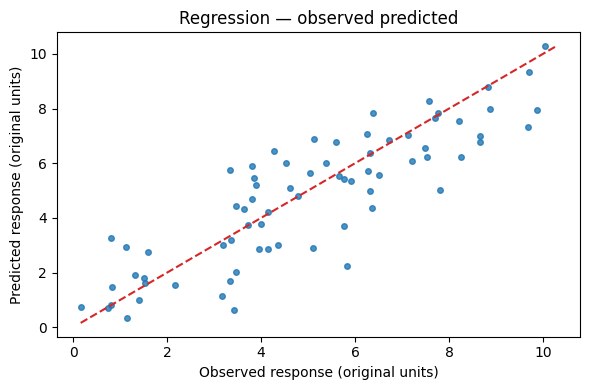

같은 최종 평가 자료의 회귀 성능
ΔR²는 선택 모형−기준 모형입니다. 값이 음수이면 최종 평가에서 개선되지 않았다는 뜻이며 그대로 보고합니다.
이 자료에서 aic의 최종 R²는 0.7272로 기준 0.7238보다 높아졌습니다(차이 +0.0034). 최종 평가를 보고 다른 후보로 바꾸지는 않습니다.

같은 최종 평가 행의 성능


,모형,r2,rmse,mae
0,기준,0.723843,1.34575,1.05102
1,aic,0.727234,1.33747,1.04788



R² 변화


,항목,값
0,선택−기준,0.00339038



선택 모형 normality


...


선택 모형 heteroscedasticity


,test,statistic,p_value,reject_h0,df_num,df_den
0,breusch_pagan LM,1.94935,0.377315,False,None,None
1,breusch_pagan F,0.968508,0.381796,False,None,None



선택 모형 independence


,test,statistic,p_value,reject_h0,df_num,df_den
0,Durbin-Watson descriptive,0.42806,NaN,None,None,None
1,Breusch-Godfrey LM,103.56,2.6662e-22,True,None,None
2,Breusch-Godfrey F,86.7822,1.57327e-33,True,None,None



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


In [7]:
ctx.run("1-6", "reg_final")

## 2. 이진 사건 예측과 샘플링

**상황을 이해하기**

전력 사용량 점수는 학습용 소비 지표이며 미납은 요금을 기한 내 내지 않은 사건입니다.

**관측 단위와 판단 목적**

한 행은 회귀와 별도로 생성한 독립 사건 관측입니다. 실제 사건을 놓치는 경우와 잘못 경보하는 경우의 비용을 구분합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 관측 식별자 |
| `target` | 1=미납 발생, 0=해당 사건 없음 |
| `c1` | 사건 전에 측정한 가상 연속 위험 신호 1 |
| `c2` | 사건 전에 측정한 가상 연속 위험 신호 2 |
| `c3` | 사건 전에 측정한 가상 연속 위험 신호 3 |
| `c4` | 사건 전에 측정한 가상 연속 위험 신호 4 |

**고정 분석 조건**

classification.csv는 별도 독립360관측의 합성 자료이며 target=1은 미납 발생이다. c1~c4는 사건 발생 전의 수치 위험 신호, id는 식별자다. 층화 학습70%/최종평가30% 분할(시드20270006), 학습3-fold ROC AUC를 사용한다. 무보완과 random_under를 비교하되 학습 폴드 안의 대치→표준화→VIF5→샘플링→L2 로지스틱 예측모형을 사용한다. C 후보는0.1·1·10이고 GridSearchCV 전수비교로 튜닝한다. 운영 임계값0.5는 사전 고정이며 false-negative 비용9·false-positive 비용1이다. 별도로 원 학습 분포의 비벌점 이진 GLM을 설명용 적합하되 예측모형과 같은 추정량이라 주장하지 않는다.

### 2-1

**문제 (8점)**

목표 사건·양성 라벨·클래스 불균형과 층화 분할을 정리하시오. 데이터 분리 전에 샘플을 보완하면 발생하는 누출과 최종평가의 자연 발생률을 유지해야 하는 이유를 설명하시오.

**핵심 산출물**

사건 정의, 양성 라벨, 클래스 수, 층화 분리 위치

**풀이 근거와 읽는 순서**

층화 분할은 사건 비율을 보존한다.

샘플링은 imblearn Pipeline의 CV fit 내부이며 검증·test는 원 발생률 그대로다.

합성 표본은 원행을 갖는 실제 관측으로 보고하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [8]:
ctx.run("2-1", "cls_design")

예측 사건과 학습·평가 분리
target=1의 실제 사건 뜻과 양성 라벨을 먼저 확인합니다. 보완한 학습 발생률과 최종 평가의 자연 발생률을 혼동하지 않습니다.

사건·분리


,항목,값
0,양성 사건,미납 발생
1,양성 라벨,1
2,학습 행,252
3,최종 평가 행,108



학습 클래스 수


,항목,값
0,0,182
1,1,70



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 2-2

**문제 (8점)**

지정 탐색과 샘플링 모듈을 연결하고 동일 학습 폴드에서 무보완/보완 후보를 비교하시오. 파라미터·CV ROC AUC·선택 후보·폴드 위치를 제시하고 검증/최종평가에는 샘플링을 수행하지 않았음을 확인하시오.

**핵심 산출물**

무보완/보완 CV AUC 비교와 선택 파라미터·fold

**풀이 근거와 읽는 순서**

동일 폴드 ROC AUC 최대 후보를 선택한다.

대치·스케일·VIF·샘플링을 폴드 안에 둔다.

Optuna는 시드·trial 예산·후보 공간을 고정하며 Grid는 지정 후보를 전수 비교한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [9]:
ctx.run("2-2", "cls_tuning")

표본 보완과 분류 설정 비교
두 후보는 같은 CV fold로 비교합니다. 표본 보완은 fit 과정에서만 실행하고 검증·최종 평가 행은 변경하지 않습니다.

학습 CV 비교


,name,cv_auc,best_params
0,none,0.705316,{'model__C': 0.1}
1,random_under,0.705109,{'model__C': 0.1}



선택


,항목,값
0,탐색,grid
1,선택 후보,none



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 2-3

**문제 (8점)**

원 학습 분포의 설명용 이진 모형에서 계수·오즈비·구간·z 검정·우도 비교·AIC/BIC를 보고하시오. 첫 선택 특성의 제곱항 추가에 대한 log-odds 사양 검토를 수행하고 가설·자유도·p값·한계를 제시하시오. OLS 잔차 정규성·보통 R²·t/F를 일괄 적용하지 마시오.

**핵심 산출물**

자연 발생률 GLM 계수·오즈비, 추가항 우도비 검정

**풀이 근거와 읽는 순서**

logit는 성공확률이 아니라 log odds의 선형 사양이다.

자연 발생률의 비벌점 GLM z/우도 추론과 표본보완·L2 예측모형은 별개다.

추가 제곱항의 우도비는 df1 점근 비교이며 비기각이 전체 사양의 증명은 아니다.

오즈비는 확률비·인과효과가 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [10]:
ctx.run("2-3", "cls_logit")

설명용 로지스틱 회귀의 계수 해석
아래는 원 학습 발생률의 비벌점 설명 모형입니다. 샘플링·L2 규제를 사용한 예측모형과 계수가 같다고 해석하지 않습니다. 오즈비는 확률비가 아닙니다.

설명용 계수·오즈비


,term,coefficient,standard_error,z_statistic,p_value,ci_lower,ci_upper,exp_coefficient
0,Intercept,-1.12706,0.162125,-6.95178,3.60707e-12,-1.44482,-0.8093,0.323984
1,feature_1,-0.488678,0.157007,-3.11245,0.00185542,-0.796407,-0.180949,0.613437
2,feature_2,-0.101978,0.155969,-0.653836,0.513218,-0.407672,0.203715,0.903049
3,feature_3,0.804418,0.168922,4.76207,1.91618e-06,0.473337,1.1355,2.23539



추가 제곱항의 우도비 검정


,항목,값
0,H0,first feature quadratic log-odds term = 0
1,H1,quadratic term is not zero
2,lr_statistic,0.84108
3,df,1
4,p_value,0.359088
5,reject_H0,False



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 2-4

**문제 (8점)**

CV 선택 뒤 최종평가의 ROC 곡선·ROC AUC·precision-recall·평균정밀도·확률 보정 그림과 Brier 점수, 고정0.5 혼동행렬을 제시하시오. 불균형에서 정확도 하나만으로 판단하는 한계를 설명하시오.

**핵심 산출물**

ROC·PR·calibration 그림, AUC·AP·Brier·고정 임계값 혼동행렬

**풀이 근거와 읽는 순서**

같은 최종행과 양성1 확률로 ROC AUC·AP·Brier를 계산한다.

AP는 기준 발생률과 함께, 보정 그림은 bin 표본수와 함께 해석한다.

샘플링이 후험확률 보정을 보장하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

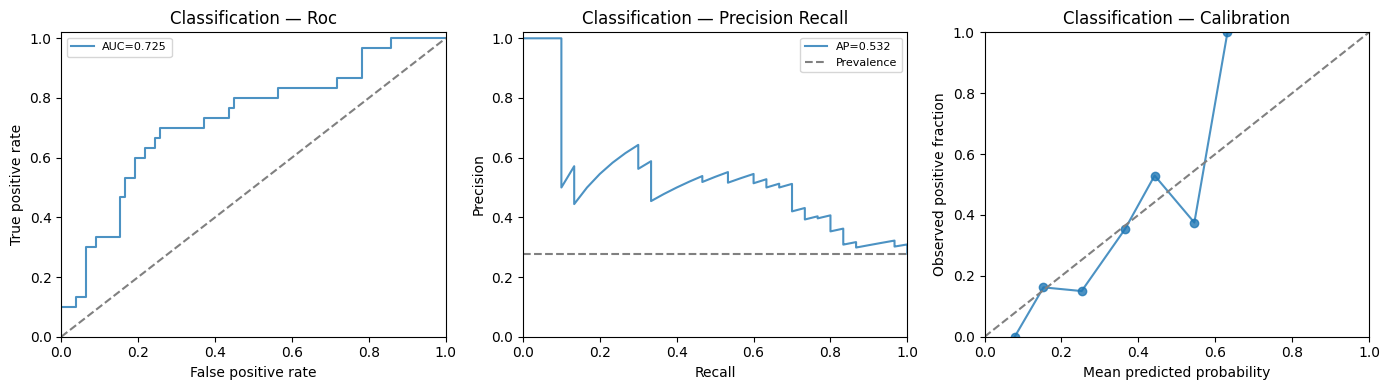

최종 분류·확률 예측 성능
ROC AUC는 순위, AP는 양성 검출의 precision/recall 요약, Brier는 확률의 제곱오차입니다. 임계값은 사전에 정한 0.5입니다.
평가 자료의 사건 비율은 27.8%, ROC AUC는 0.7252, AP는 0.5325, Brier는 0.1737입니다. 높은 순위 성능만으로 확률 보정이나 운영 비용의 적절성을 증명하지 않습니다.

최종 성능


,항목,값
0,roc_auc,0.725214
1,average_precision,0.532478
2,brier,0.173744
3,prevalence,0.277778
4,threshold,0.5



고정 0.5의 혼동행렬


,예측 0,예측 1
실제 0,73,5
실제 1,24,6



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


In [11]:
ctx.run("2-4", "cls_final")

### 2-5

**문제 (8점)**

사전 지정 비용과 임계값으로 최종평가 오분류 비용을 계산하고 운영 의사결정을 제안하시오. AUC·확률 보정·분류 임계값의 차이, 샘플링에 따른 발생률 변화와 별도 학습 검증 필요성을 설명하시오. 최종평가를 보고 새 임계값을 최적화하지 마시오.

**핵심 산출물**

FN/FP 비용 계산과 별도 운영 검증 제안

**풀이 근거와 읽는 순서**

비용=FN×지정비용+FP×1이다.

임계값0.5를 사전 고정했으므로 test에서 유리한 값으로 바꾸지 않는다.

운영 임계값·확률 재보정은 별도 학습 검증/OOF에서 사전 결정해야 한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [12]:
ctx.run("2-5", "cls_decision")

고정 임계값의 오분류 비용
비용 = 놓친 실제 사건(FN)×누락 비용 + 잘못 경보한 사건(FP)×오경보 비용입니다. 이 자료로 유리한 새 임계값을 고르지 않습니다.
지정한 누락 비용 9와 오경보 비용 1를 적용한 최종 총비용은 221입니다. 이 비용을 줄일 새 임계값은 별도 학습 검증에서 정해야 합니다.

사전 비용의 실제 결과


,항목,값
0,false_negative_cost,9
1,false_positive_cost,1
2,holdout_cost_at_prespecified_half,221



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


## 3. 미래 수요와 시간순 검증

**상황을 이해하기**

전력 사용량 점수는 학습용 소비 지표이며 미납은 요금을 기한 내 내지 않은 사건입니다.

**관측 단위와 판단 목적**

한 행은 하루입니다. 앞 두 자료와 결합하지 않는 별도의 140일 합성 시계열입니다. 앞으로 7일의 값을 예측하고 단순 기준 예측과 같은 날짜에서 비교합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `date` | 중복 없는 등간격 날짜 |
| `target` | 일별 수요/사용량의 학습용 연속 지표; 회귀·분류 target과 별개 |

**고정 분석 조건**

timeseries.csv는 에너지 사용량의 별도140일 합성 수요/사용 기록이다. date는 중복 없는 등간격 일자, target은 별도의 연속 수요 지표이며 회귀/분류의 target과 대상·단위가 다르다. 공변량 예측은 사용하지 않는다. 마지막7일은 최종 미래 평가로 봉인한다. 학습의 마지막14일을 두 구간으로 나눠 각각 직전까지 확장 학습하고7일씩 예측한다. 차수 후보(0,0,0)·(1,0,0)를 rolling 평균 RMSE로 선택한다. 계절 주기는7이며 각 후보에 계절(1,0,0,7)을 고정한다. 기준은 직전7일 반복이다. 예측구간 신뢰수준95%이고 최적화 최대100회다. 회귀/분류 자료와는 다른 과제다.

### 3-1

**문제 (6점)**

시간 간격·순서·목표·예측 horizon을 확인하고 과거/최종 미래를 나누시오. 학습의 정상성 진단 가설·통계량·p값과 추세·계절성의 한계를 설명하시오. 무작위 CV가 부적절한 이유를 서술하시오.

**핵심 산출물**

시간·horizon·과거/미래 경계와 과거 ADF 진단

**풀이 근거와 읽는 순서**

과거에서만 정상성(단위근 귀무) 진단을 수행한다.

ADF 비기각은 단위근 확정이 아니며 추세·계절 사양과 작은 표본의 한계를 함께 확인한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [13]:
ctx.run("3-1", "ts_design")

시간 순서와 예측 구간 설계
한 행은 하루입니다. 마지막 7일은 미래 평가이며, 차수 선택이나 정상성 진단에 포함하지 않습니다.

시간 분리


,항목,값
0,n,140
1,frequency,daily
2,period,7
3,train_end,2024-05-12 00:00:00
4,test_start,2024-05-13 00:00:00
5,horizon,7



과거 자료의 ADF


,항목,값
0,test_type,adf
1,statistic,-0.400038
2,p_value,0.910092
3,reject_h0,False
4,alpha,0.05
5,null_hypothesis,시계열에 단위근이 존재한다
6,alternative,omnibus
7,method_used,augmented-dickey-fuller
8,used_lag,12
9,nobs,120



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 3-2

**문제 (6점)**

지정 expanding rolling 검증을 구현하여 후보별 RMSE·MAE·수렴/실패, 각 과거/검증 구간을 제시하고 차수를 선택하시오. 최종 미래값을 차수·전처리 선택에 사용하지 마시오.

**핵심 산출물**

rolling 구간·차수별 오차·수렴 기록과 선택 차수

**풀이 근거와 읽는 순서**

각 rolling train은 validation보다 앞서고 모든 validation은 최종test보다 앞선다.

후보 적합 실패·미수렴은 기록하고 적격 후보의 평균 RMSE로 선택한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [14]:
ctx.run("3-2", "ts_tuning")

과거 구간에서 차수 비교
각 검증 구간보다 앞선 날만 학습에 사용합니다. 선택 기준은 과거 rolling 평균 RMSE입니다.

rolling 후보 비교


/Users/finn/.codex/.chatgpt-projects/g-p-6aca50e7dc108191af63ef7e071957e4/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'
/Users/finn/.codex/.chatgpt-projects/g-p-6aca50e7dc108191af63ef7e071957e4/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'
/Users/finn/.codex/.chatgpt-projects/g-p-6aca50e7dc108191af63ef7e071957e4/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/finn/.codex/.chatgpt-projects/g-p-6aca50e7dc108191af63ef7e071957

,order,cv_rmse,cv_mae,error
0,"[0, 0, 0]",1.3898,1.13788,None
1,"[1, 0, 0]",1.30083,1.07629,None



선택 차수


,항목,값
0,order,"[1, 0, 0]"



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 3-3

**문제 (6점)**

선택 모형의 학습 AIC·BIC와 초기화 구간을 제외한 잔차 자기상관 진단을 보고하시오. 추정한 AR/MA 자유도를 반영하고 가설·통계량·p값·판정·해석을 제시하시오. 차분이나 우도 정의가 다른 모형의 정보량 단순 비교를 경계하시오.

**핵심 산출물**

AIC·BIC, 자유도 보정 잔차 검정과 해석

**풀이 근거와 읽는 순서**

Ljung-Box는 지정 지연까지 자기상관 없음이 귀무이며 AR/MA p+q+P+Q를 자유도에서 차감한다.

초기화 구간을 제외한다.

비기각은 모든 독립성의 증명이 아니며 AIC/BIC는 학습 적합 기준이다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [15]:
ctx.run("3-3", "ts_diagnostics")

선택 시계열 모형의 잔차 진단
Ljung–Box는 지정 지연까지의 자기상관을 진단합니다. 비기각은 모든 형태의 독립성 증명이 아니며 AIC/BIC는 예측 오차가 아닙니다.

학습 정보량


,항목,값
0,aic,376.437
1,bic,385.108



잔차 진단


,항목,값
0,aic,376.437
1,bic,385.108
2,burn,7
3,model_df,2
4,lag,14
5,ljung_box_statistic,48.8054
6,ljung_box_p_value,2.2621e-06



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


### 3-4

**문제 (6점)**

선택 모형과 지정 naive의 동일 미래7일 RMSE·MAE·R²·MASE를 비교하고 예측·관측·조건부 예측구간을 시각화하시오. MASE의 학습 분모, 음의 보류 R² 가능성, 차수 선택 불확실성을 구간이 모두 반영하지 않는 한계를 설명하시오.

**핵심 산출물**

같은 미래의 선택/naive 비교, MASE 분모와 예측구간

**풀이 근거와 읽는 순서**

동일 미래 horizon에서 선택/naive를 비교한다.

MASE 분모는 train의 주기별 차이 절대평균이며0이면 정의하지 않는다.

예측구간은 선택 모형에 조건부이며 차수 선택·모형 오사양 불확실성을 전부 포함하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

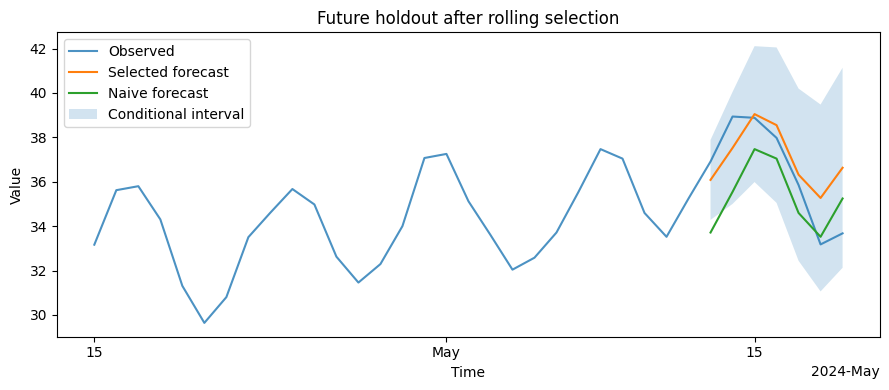

미래 관측과 단순 기준 예측 비교
naive는 직전 값 또는 직전 7일을 반복하는 단순 기준입니다. 같은 미래 날짜로 비교하며 MASE의 분모는 과거 학습 자료로만 계산합니다.
같은 미래 7일의 RMSE는 선택 모형 1.5293, 단순 기준 2.0276입니다. 이번 미래 구간에서는 선택 모형의 오차가 더 작습니다. 이 비교와 학습 기준으로 표준화한 MASE를 구분합니다.

동일 미래 성능


,모형,rmse,mae,r2
0,selected,1.52931,1.21367,0.509803
1,baseline,2.02765,1.72979,0.138278



날짜 순서의 예측·관측·구간


,truth,predictions,baseline_predictions,interval_lower,interval_upper
0,36.9105,36.0825,33.7117,34.2813,37.8836
1,38.9374,37.5228,35.5435,34.9997,40.0459
2,38.8796,39.0466,37.4695,35.9854,42.1079
3,37.9753,38.549,37.0414,35.0472,42.0508
4,35.8527,36.3173,34.5937,32.4384,40.1963
5,33.176,35.2684,33.5187,31.0583,39.4784
6,33.6746,36.6299,35.2446,32.1241,41.1358



MASE


,항목,값
0,mase_denominator,1.00504
1,mase,1.20758



전체 정밀 수치·원행 위치·경고: 실행결과/답안수치.json


In [16]:
ctx.run("3-4", "ts_final")